# Flood Mapping in Emilia-Romagna with Sentinel-1 SAR

We map the **May 2023 Emilia-Romagna flood** (Bassa Romagna: Lugo, Conselice, Bagnacavallo) with **Sentinel-1 GRD (VV + VH, σ⁰ in dB)** and compare two approaches against the **Copernicus EMS EMSR664** reference map:
- **Otsu thresholding** → (a) post-event image only · (b) post − pre change detection
- a **small U-Net written from scratch in PyTorch**, trained on **Sen1Floods11 (hand-labeled)** and applied **zero-shot** to Emilia-Romagna (domain shift)

## Decision log

Every real choice (and every dead end) has a box above the cell where it is made.

| # | Decision | Choice | Rejected | Section |
|---|---|---|---|---|
| 1 | Case study | Emilia-Romagna, May 2023 (EMSR664) | Liguria Nov 2014 (EMSR112) · Emilia-Romagna Sep 2024 / Oct 2024 / Mar 2025 | 1 |

## 0. Setup

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import rasterio
import geopandas as gpd
import skimage
import torch
import openeo

SEED = 4
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("data")        # GeoTIFF, EMS vectors, Sen1Floods11 (not on GitHub)
MODELS_DIR = Path("models")    # U-Net weights (not on GitHub)
FIGURES_DIR = Path("figures")  # PNG and GIF for the README
for folder in [DATA_DIR, MODELS_DIR, FIGURES_DIR]:
    folder.mkdir(exist_ok=True)

print("numpy", np.__version__, "| torch", torch.__version__, "| openeo", openeo.__version__, "| rasterio", rasterio.__version__)

numpy 2.5.4 | torch 2.15.0+cpu | openeo 0.54.0 | rasterio 1.5.2


In [3]:
# GPU check → decides where we train the U-Net (section 10)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("CUDA available:", torch.cuda.is_available())
print("Device:", DEVICE)
print("CPU threads:", torch.get_num_threads())

CUDA available: False
Device: cpu
CPU threads: 6


### Copernicus Data Space Ecosystem login

We download Sentinel-1 through the **openEO** backend of the Copernicus Data Space Ecosystem (CDSE). The first time, `authenticate_oidc()` prints a link → we log in in the browser with the CDSE account → the token is then cached and refreshed automatically.

In [4]:
OPENEO_URL = "openeo.dataspace.copernicus.eu"

connection = openeo.connect(OPENEO_URL).authenticate_oidc()

print("Sentinel-1 GRD available:", "SENTINEL1_GRD" in connection.list_collection_ids())
print("Logged in as:", connection.describe_account()["name"])  # only the name → no email in the public repo

Authenticated using refresh token.
Sentinel-1 GRD available: True
Logged in as: Daniel Di Somma


## 1. Area and event

Originally I wanted to cover floods on the Liguria region, but since the morphology is more complicated, the results would be less clear.

That's why we're analyzing **Emilia-Romagna** in **May 2023**, where persistent rain hit the region in **two waves**, resulting in catastrophic events such as floods, river overflows and landslides:
- **1–3 May 2023**: first heavy rain, rivers overflow on **2–3 May** (Copernicus EMS activation **EMSR659**)
- **15–17 May 2023**: second, even stronger rain on soil that was already saturated → more than 20 rivers overflow on **16–17 May**, the plain around Lugo, Conselice and Bagnacavallo is flooded for weeks


### Which Sentinel-1 images we use

To find the Sentinel-1 passes over the flooded area, we used the **Copernicus Browser** (browser.dataspace.copernicus.eu):
1. We centred the map on **Lugo (RA)**.
2. We selected **Sentinel-1 → C-SAR → Level-1 GRD**.
3. We set the time range from **2023-04-25** to **2023-05-25**.


| Date | Time (UTC) | Orbit direction | Use |
|---|---|---|---|
| 28/04/2023 | ~05:19 | descending | **pre-event** |
| 29/04/2023 | ~17:06 | ascending | – |
| 10/05/2023 | ~05:19 | descending | problem: water from the 2–3 May flood is still there |
| 11/05/2023 | ~17:06 | ascending | – |
| **22/05/2023** | **~05:19** | descending | **post-event** |
| 23/05/2023 | ~17:06 | ascending | – |

In 2023 only **Sentinel-1A** was flying, so the same area is seen from the **same orbit every 12 days** (28/04 → 10/05 → 22/05). Pre and post images from the same orbit have the **same viewing geometry**, so we can compare them pixel by pixel.

We pick **22 May** as post-event image because it is the closest descending pass after the peak (16–17 May), and **28 April** as pre-event image because it is the last one before the floods of May.

For the reference map we use the Copernicus EMS product **EMSR664 AOI01 DEL MONIT03**: its flood extent comes from a **COSMO-SkyMed** image of **21 May at 16:50 UTC** (written in the `source` table and in the PDF map inside the zip), about **12 hours before** our Sentinel-1 pass. Earlier EMS maps (17, 18, 20 May) show more water, which had already drained by 22 May.

In [5]:
# EMS flood map, downloaded by hand from the EMSR664 page and unzipped into data/
EMS_DIR = DATA_DIR / "EMSR664_AOI01_DEL_MONIT03_v1"

flood_ems = gpd.read_file(EMS_DIR / "EMSR664_AOI01_DEL_MONIT03_observedEventA_v1.shp")  # flooded areas
aoi_ems = gpd.read_file(EMS_DIR / "EMSR664_AOI01_DEL_MONIT03_areaOfInterestA_v1.shp")   # mapped area

print("flood polygons:", len(flood_ems), "| CRS:", flood_ems.crs)
flood_ems.head()

flood polygons: 1245 | CRS: EPSG:4326


,event_type,obj_desc,det_method,notation,dmg_src_id,area,geometry
0,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.053375,"POLYGON ((12.11537 44.35073, 12.11537 44.35072..."
1,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.085192,"POLYGON ((12.12645 44.40939, 12.12648 44.40938..."
2,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.031632,"POLYGON ((11.96852 44.50582, 11.9685 44.50581,..."
3,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.063630,"POLYGON ((11.95884 44.55308, 11.95882 44.55303..."
4,5-Flood,Riverine flood,Semi-automatic extraction,Flooded area,7,0.754732,"POLYGON ((12.02744 44.43376, 12.02746 44.43369..."


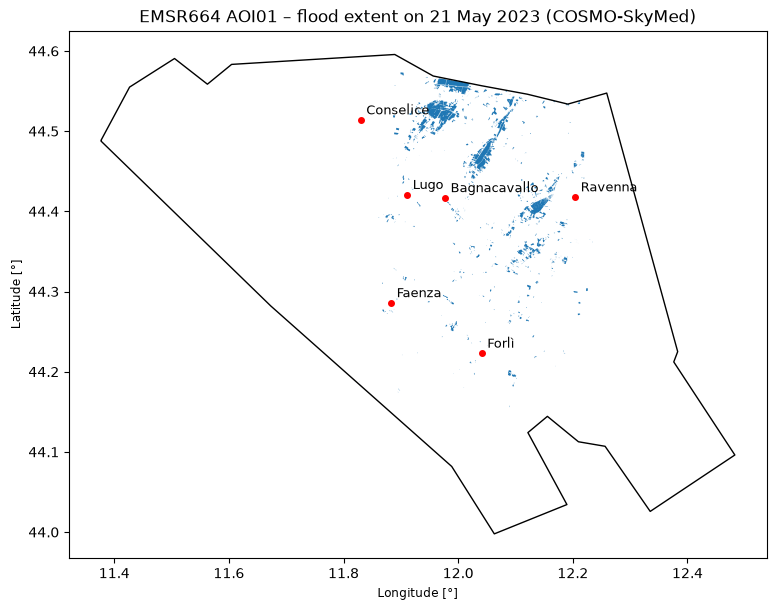

In [6]:
# Where is the water? EMS flood polygons inside the EMS area of interest
TOWNS = {                        # (longitude, latitude), only to orient ourselves on the map
    "Lugo": (11.911, 44.421),
    "Conselice": (11.830, 44.514),
    "Bagnacavallo": (11.977, 44.417),
    "Faenza": (11.883, 44.286),
    "Ravenna": (12.204, 44.418),
    "Forlì": (12.041, 44.223),
}

fig, ax = plt.subplots(figsize=(9, 8))
aoi_ems.boundary.plot(ax=ax, color="black", linewidth=1)   # contour of the area analysed by EMS
flood_ems.plot(ax=ax, color="tab:blue")                    # flooded areas on 21 May

for name, (lon, lat) in TOWNS.items():
    ax.plot(lon, lat, "o", color="red", markersize=4)
    ax.annotate(name, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=9)

ax.set_title("EMSR664 AOI01 – flood extent on 21 May 2023 (COSMO-SkyMed)")
ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")
plt.show()

### What the map tells us

The water is concentrated in the **north-eastern plain**: Conselice, Lugo, Bagnacavallo, Ravenna. Towards Faenza and Forlì there is little.

So we don't need to download Sentinel-1 over the whole EMS area (about 90 × 65 km): a **rectangle around the flooded zone** is enough.

In [7]:
from shapely.geometry import box

# Rectangle we will download from Sentinel-1 (degrees, EPSG:4326), same format openEO wants
BBOX = {"west": 11.85, "south": 44.30, "east": 12.20, "north": 44.58}

bbox_gdf = gpd.GeoDataFrame(geometry=[box(BBOX["west"], BBOX["south"], BBOX["east"], BBOX["north"])], crs="EPSG:4326")

# Degrees are not metres → reproject to UTM zone 32N (metres) to measure sizes and areas
bbox_utm = bbox_gdf.to_crs("EPSG:32632")
flood_utm = flood_ems.to_crs("EPSG:32632")
aoi_utm = aoi_ems.to_crs("EPSG:32632")

xmin, ymin, xmax, ymax = bbox_utm.total_bounds
print(f"BBOX size: {(xmax - xmin) / 1000:.1f} km x {(ymax - ymin) / 1000:.1f} km, about {(xmax - xmin) / 10:.0f} x {(ymax - ymin) / 10:.0f} pixels at 10 m")

water_in_bbox = flood_utm.clip(bbox_utm).area.sum()   # m², only the water inside the rectangle
print(f"Water fraction: BBOX {100 * water_in_bbox / bbox_utm.area.sum():.1f}% vs whole AOI {100 * flood_utm.area.sum() / aoi_utm.area.sum():.1f}%")

BBOX size: 29.0 km x 32.1 km, about 2900 x 3213 pixels at 10 m
Water fraction: BBOX 4.8% vs whole AOI 1.4%


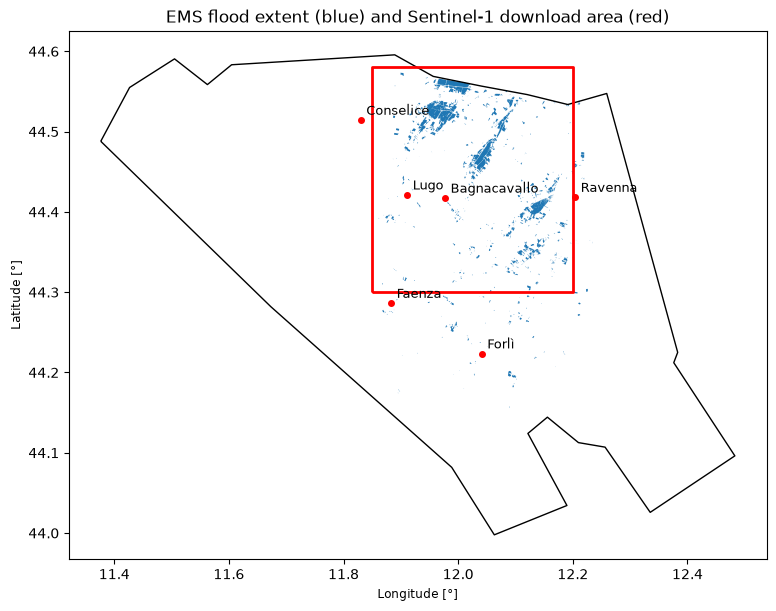

In [8]:
# Same map as before + the rectangle in red
fig, ax = plt.subplots(figsize=(9, 8))
aoi_ems.boundary.plot(ax=ax, color="black", linewidth=1)
flood_ems.plot(ax=ax, color="tab:blue")
bbox_gdf.boundary.plot(ax=ax, color="red", linewidth=2)   # area we download from Sentinel-1

for name, (lon, lat) in TOWNS.items():
    ax.plot(lon, lat, "o", color="red", markersize=4)
    ax.annotate(name, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=9)

ax.set_title("EMS flood extent (blue) and Sentinel-1 download area (red)")
ax.set_xlabel("Longitude [°]")
ax.set_ylabel("Latitude [°]")
plt.show()

## 2. Sentinel-1 download with openEO

We ask the CDSE openEO backend for the two Sentinel-1 images (pre 28 April, post 22 May) over our rectangle, with bands **VV** and **VH**.

- We request **σ⁰ (sigma0-ellipsoid)** and not γ⁰ terrain-flattened, because the U-Net will be trained on **Sen1Floods11**, which uses σ⁰. Same kind of input as in training. On a flat plain the difference is anyway small.
- We download **linear** σ⁰ and convert it to **dB** later in numpy.
- We force both images onto the **same 10 m grid in UTM 32N (EPSG:32632)**. Our rectangle crosses 12° E, the border between UTM zones 32 and 33, so without this the backend could pick a different grid for each image. With the same grid, pre, post and the EMS mask line up pixel by pixel.

In [9]:
POST_DATE = "2023-05-22"
PRE_DATE = "2023-04-28"
UTM_EPSG = 32632    # UTM zone 32N, metres
PIXEL_SIZE = 10     # metres


def download_s1(date, output_file):
    """Download Sentinel-1 sigma0 (linear) VV + VH for one date over BBOX as a GeoTIFF."""
    if output_file.exists():                    # already downloaded → skip the ~5 min batch job
        print("already there:", output_file)
        return
    next_day = str(np.datetime64(date) + np.timedelta64(1, "D"))   # temporal extent: end date is excluded
    cube = connection.load_collection(
        "SENTINEL1_GRD",
        spatial_extent=BBOX,
        temporal_extent=[date, next_day],
        bands=["VV", "VH"],
    )
    cube = cube.sar_backscatter(coefficient="sigma0-ellipsoid")                    # calibration → sigma0
    cube = cube.resample_spatial(resolution=PIXEL_SIZE, projection=UTM_EPSG)       # same 10 m UTM grid for every image
    cube = cube.reduce_dimension(dimension="t", reducer="mean")                    # one date only → drop the time axis
    cube.execute_batch(outputfile=output_file, out_format="GTiff", title=f"S1 {date}")
    print("saved:", output_file)


POST_FILE = DATA_DIR / "s1_post_20230522.tif"
download_s1(POST_DATE, POST_FILE)

already there: data\s1_post_20230522.tif


In [10]:
# Same recipe for the pre-event image (same orbit 95, 12 days × 2 earlier)
PRE_FILE = DATA_DIR / "s1_pre_20230428.tif"
download_s1(PRE_DATE, PRE_FILE)

already there: data\s1_pre_20230428.tif


In [11]:
def read_s1_db(path):
    """Read a 2-band (VV, VH) sigma0 GeoTIFF and convert it from linear to dB."""
    with rasterio.open(path) as src:
        sigma0 = src.read()          # (2, rows, cols), linear power, band order VV, VH
        profile = src.profile        # grid info: CRS, transform, width, height → needed later for the EMS mask
    sigma0_db = 10 * np.log10(sigma0)
    return sigma0_db, profile


post_db, profile = read_s1_db(POST_FILE)   # (2, rows, cols)
pre_db, _ = read_s1_db(PRE_FILE)           # same grid → we keep only one profile

pre_db.shape, post_db.shape

((2, 3214, 2901), (2, 3214, 2901))

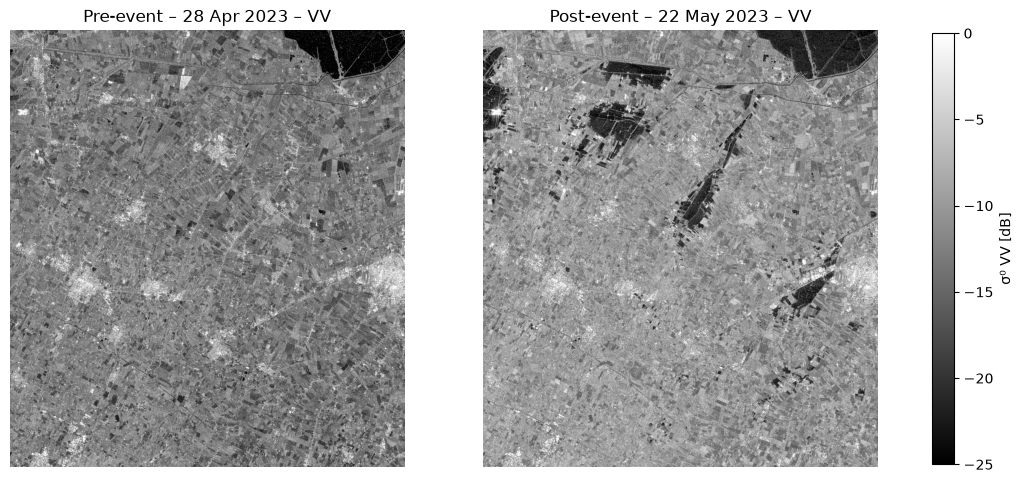

In [12]:
# Pre vs post, VV band, same fixed colour scale → same grey = same dB value in both images
VMIN, VMAX = -25, 0     # dB: calm water ≈ -25, buildings ≈ 0

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, image, title in zip(axes, [pre_db, post_db], ["Pre-event – 28 Apr 2023", "Post-event – 22 May 2023"]):
    im = ax.imshow(image[0], cmap="gray", vmin=VMIN, vmax=VMAX)   # image[0] = VV
    ax.set_title(f"{title} – VV")
    ax.axis("off")

fig.colorbar(im, ax=axes, shrink=0.7, label="σ⁰ VV [dB]")
plt.show()

## 3. Exploration

Before classifying anything, we look at the data up close: what flooded fields, roads, villages and **speckle** look like at full resolution, and how water and land are distributed in the histograms.

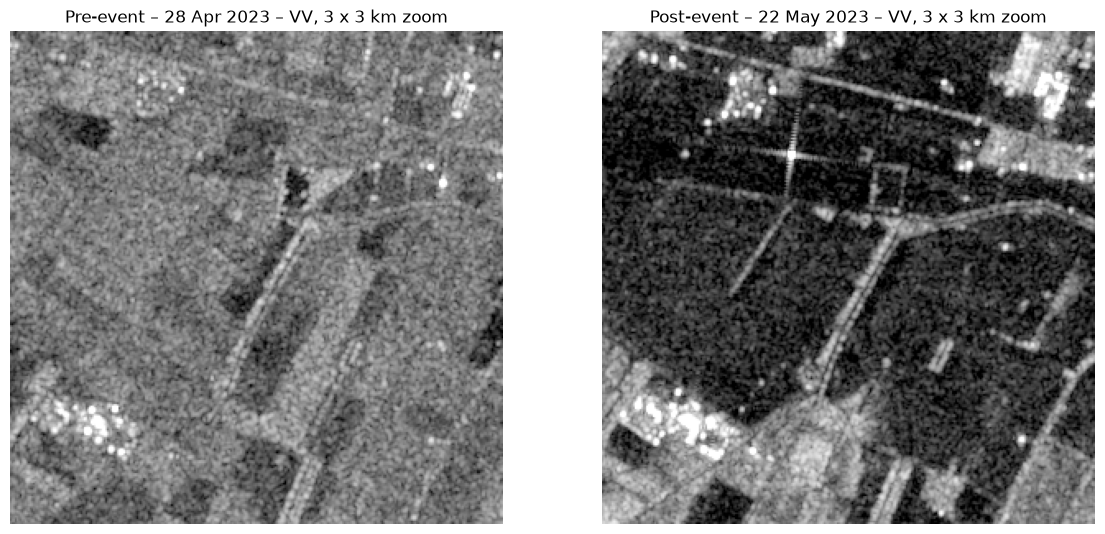

(300, 300)

In [13]:
# Zoom on a 3 x 3 km window (300 x 300 pixels) north of Lugo, inside the largest EMS flood polygon
ZOOM_ROWS = slice(550, 850)    # image rows    (north → south)
ZOOM_COLS = slice(800, 1100)   # image columns (west → east)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, image, title in zip(axes, [pre_db, post_db], ["Pre-event – 28 Apr 2023", "Post-event – 22 May 2023"]):
    ax.imshow(image[0, ZOOM_ROWS, ZOOM_COLS], cmap="gray", vmin=VMIN, vmax=VMAX)   # VV, only the window
    ax.set_title(f"{title} – VV, 3 x 3 km zoom")
    ax.axis("off")
plt.show()

post_db[0, ZOOM_ROWS, ZOOM_COLS].shape   # (300, 300)

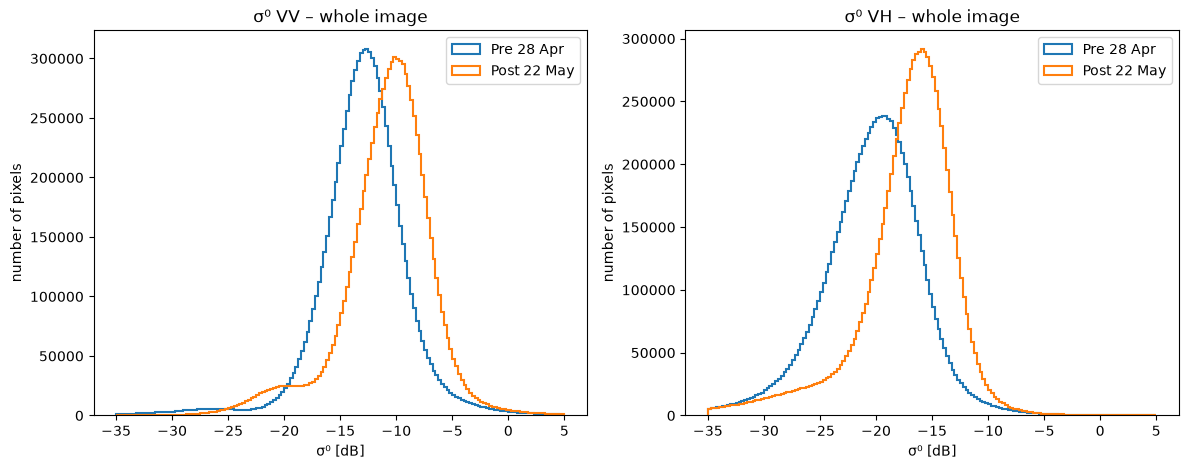

(9288497,)

In [14]:
# Histograms of the whole image: is there a separate "water" peak? (Otsu needs two peaks)
BINS = np.linspace(-35, 5, 161)   # dB, bins 0.25 dB wide

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for band, (ax, name) in enumerate(zip(axes, ["VV", "VH"])):
    for image, label in zip([pre_db, post_db], ["Pre 28 Apr", "Post 22 May"]):
        values = image[band].ravel()            # (rows * cols,) all pixels of one band in a 1D array
        values = values[np.isfinite(values)]    # drop -inf / NaN (log10 of 0 at the image border)
        ax.hist(values, bins=BINS, histtype="step", linewidth=1.5, label=label)
    ax.set_title(f"σ⁰ {name} – whole image")
    ax.set_xlabel("σ⁰ [dB]")
    ax.set_ylabel("number of pixels")
    ax.legend()
plt.show()

values.shape   # number of valid pixels (last band plotted)

Before thresholding, we checked the histograms. In **VV** the flood shows up as a small **shoulder around −21 dB**, in **VH** the water doesn't separate at all, so we threshold **VV**.

Dry land also got about 3 dB brighter after the event (wet soil, growing crops), so a post − pre difference won't be zero on dry land either.

## 4. Ground truth from EMS

To measure how good a flood map is, we need the reference **on the same pixels** as Sentinel-1. So we turn the EMS polygons into a raster on our 10 m grid (**rasterization**), with three values, the same convention as **Sen1Floods11**:
- **1** = flooded (inside an EMS flood polygon)
- **0** = not flooded (analysed by EMS, no water)
- **−1** = no data, ignored in the metrics: outside the EMS area of interest, or marked by EMS as **"Not Analysed – No data"** (outside the COSMO-SkyMed image)

In [15]:
from rasterio.features import rasterize

# Areas EMS did not analyse (outside the COSMO-SkyMed image), in UTM like the other layers
footprint_ems = gpd.read_file(EMS_DIR / "EMSR664_AOI01_DEL_MONIT03_imageFootprintA_v1.shp")
not_analysed_utm = footprint_ems[footprint_ems["obj_type"] == "Not Analysed - No data"].to_crs(UTM_EPSG)

GRID_SHAPE = (profile["height"], profile["width"])   # (3214, 2901) rows, cols of the Sentinel-1 images
GRID_TRANSFORM = profile["transform"]                 # pixel (row, col) <-> UTM coordinates in metres


def polygons_to_mask(gdf):
    """1 where the pixel centre falls inside a polygon, 0 elsewhere, on the Sentinel-1 grid."""
    return rasterize(gdf.geometry, out_shape=GRID_SHAPE, transform=GRID_TRANSFORM,
                     fill=0, default_value=1, dtype="uint8")


flooded = polygons_to_mask(flood_utm)              # (rows, cols) 1 = EMS water
inside_aoi = polygons_to_mask(aoi_utm)             # (rows, cols) 1 = analysed by EMS
not_analysed = polygons_to_mask(not_analysed_utm)  # (rows, cols) 1 = no data

# Build the labels: start with everything ignored, then fill in. The order matters: no data wins
labels = np.full(GRID_SHAPE, -1, dtype=np.int8)
labels[inside_aoi == 1] = 0
labels[flooded == 1] = 1
labels[not_analysed == 1] = -1

for value, name in [(1, "flooded"), (0, "not flooded"), (-1, "ignored")]:
    print(f"{name:12s} {value:3d}: {100 * np.mean(labels == value):5.1f}% of pixels")

labels.shape

flooded        1:   4.5% of pixels
not flooded    0:  79.9% of pixels
ignored       -1:  15.6% of pixels


(3214, 2901)

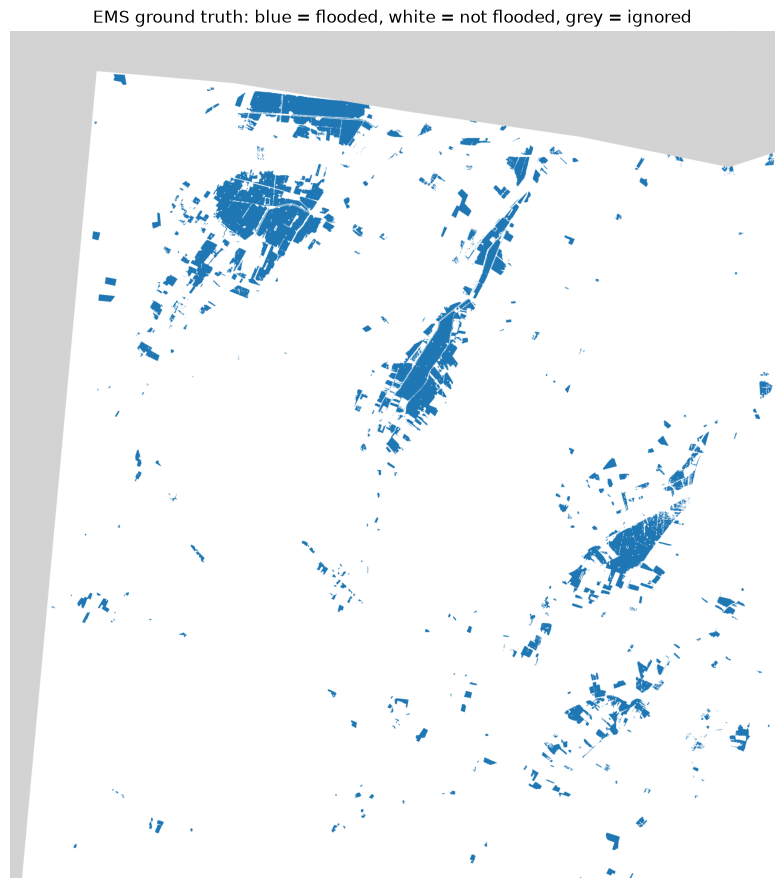

In [16]:
from matplotlib.colors import ListedColormap

# One colour per label value, in order -1, 0, 1
LABEL_CMAP = ListedColormap(["lightgrey", "white", "tab:blue"])   # ignored, not flooded, flooded

fig, ax = plt.subplots(figsize=(10, 11))
ax.imshow(labels, cmap=LABEL_CMAP, vmin=-1, vmax=1)   # ground truth on the Sentinel-1 grid
ax.set_title("EMS ground truth: blue = flooded, white = not flooded, grey = ignored")
ax.axis("off")
plt.show()

The mask and the image line up pixel by pixel for two reasons, both prepared in the previous sections:
- **Same coordinate system**: images and polygons are all in **UTM 32N (metres)**. We forced it in the openEO download and with `.to_crs(...)` on the polygons.
- **Same grid**: to rasterize the polygons we used the **transform of the Sentinel-1 image itself**, i.e. the rule that converts a pixel (row, col) into metres. So pixel (600, 900) of the mask covers exactly the same 10 × 10 m of ground as pixel (600, 900) of the image.

To check it, we draw the EMS polygons on top of the post-event image.

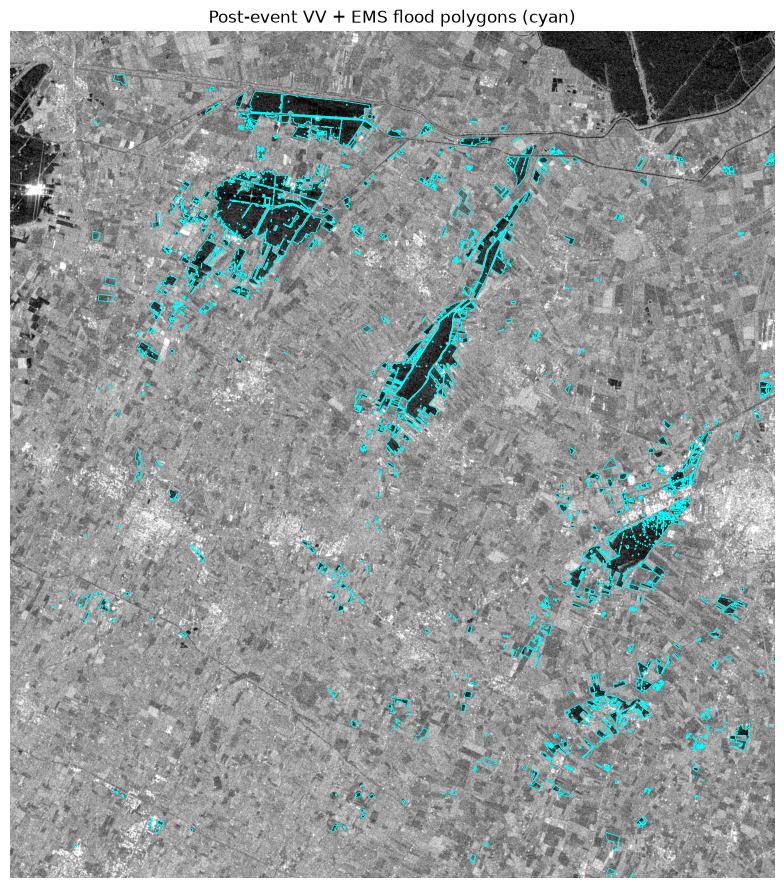

In [17]:
from rasterio.plot import plotting_extent

# Put the image in UTM metres (instead of pixel indices) so that the EMS polygons land on top of it
EXTENT = plotting_extent(post_db[0], GRID_TRANSFORM)   # (west, east, south, north) in metres

fig, ax = plt.subplots(figsize=(10, 11))
ax.imshow(post_db[0], cmap="gray", vmin=VMIN, vmax=VMAX, extent=EXTENT)   # post-event VV
flood_utm.boundary.plot(ax=ax, color="cyan", linewidth=0.6)               # EMS flood polygons (outline only)
ax.set_xlim(EXTENT[0], EXTENT[1])    # keep the view on our image (EMS polygons go beyond it)
ax.set_ylim(EXTENT[2], EXTENT[3])
ax.set_title("Post-event VV + EMS flood polygons (cyan)")
ax.axis("off")
plt.show()

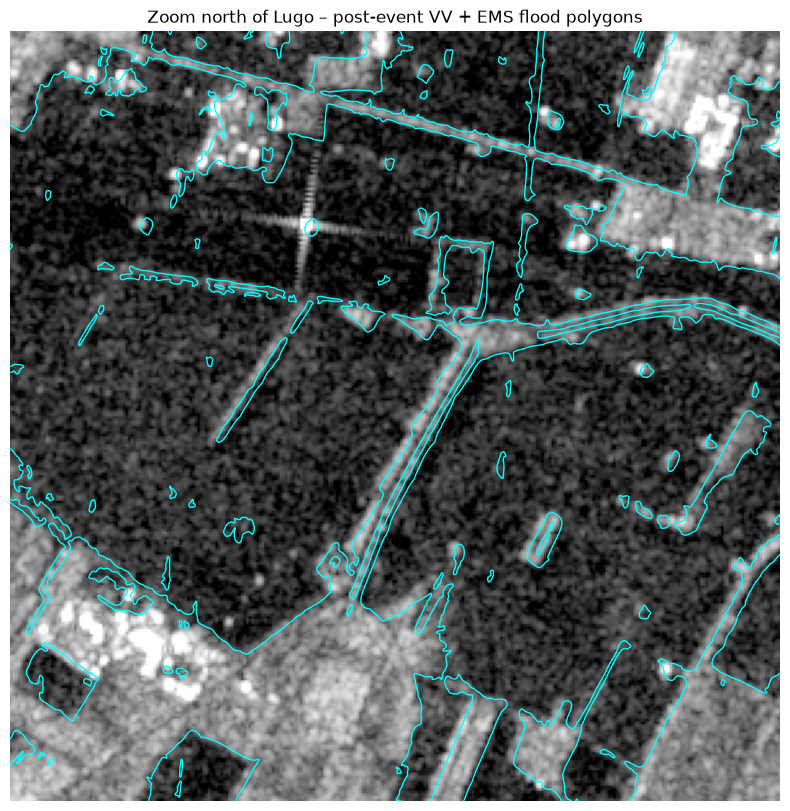

In [18]:
# Same overlay, zoomed on the 3 x 3 km window of section 3
# Corners of the window: pixel (col, row) -> UTM (x, y)
zoom_west, zoom_north = GRID_TRANSFORM * (ZOOM_COLS.start, ZOOM_ROWS.start)
zoom_east, zoom_south = GRID_TRANSFORM * (ZOOM_COLS.stop, ZOOM_ROWS.stop)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(post_db[0], cmap="gray", vmin=VMIN, vmax=VMAX, extent=EXTENT)
flood_utm.boundary.plot(ax=ax, color="cyan", linewidth=1)
ax.set_xlim(zoom_west, zoom_east)    # move the "camera" onto the window, nothing is cut
ax.set_ylim(zoom_south, zoom_north)
ax.set_title("Zoom north of Lugo – post-event VV + EMS flood polygons")
ax.axis("off")
plt.show()

The EMS outlines follow the edges of the dark fields almost pixel by pixel, while roads, embankments and villages stay outside. Our ground truth is ready: **4.5% flooded, 79.9% not flooded, 15.6% ignored**.